Load the dataset

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/Customer_churn_cleaned.csv')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Check column names
print(df.columns)

# Check data types
df.info()

# Check missing values
print(df.isnull().sum())

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   obj

Customer Churn Analysis

In [6]:
total_customers = len(df)
churned = (df['Churn'] == 'Yes').sum()
retained = (df['Churn'] == 'No').sum()

churn_rate = (churned / total_customers) * 100
retention_rate = (retained / total_customers) * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned)
print("Retained Customers:", retained)
print("Churn Rate:", round(churn_rate, 2), "%")
print("Retention Rate:", round(retention_rate, 2), "%")

Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Churn Rate: 26.54 %
Retention Rate: 73.46 %


Churn by contract type

In [7]:
contract_analysis = df.groupby('Contract').agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn', lambda x: (x == 'Yes').sum())
)

contract_analysis['Churn_Rate'] = (
    contract_analysis['Churned_Customers'] /
    contract_analysis['Total_Customers'] * 100
).round(2)

contract_analysis

,Total_Customers,Churned_Customers,Churn_Rate
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


Churn by internet service
  

In [8]:
internet_analysis = df.groupby('InternetService').agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn', lambda x: (x == 'Yes').sum())
)

internet_analysis['Churn_Rate'] = (
    internet_analysis['Churned_Customers'] /
    internet_analysis['Total_Customers'] * 100
).round(2)

internet_analysis

,Total_Customers,Churned_Customers,Churn_Rate
InternetService,,,
DSL,2421,459,18.96
Fiber optic,3096,1297,41.89
No,1526,113,7.40


Churn by payment method

In [9]:
payment_analysis = df.groupby('PaymentMethod').agg(
    Total_Customers=('customerID', 'count'),
    Churned_Customers=('Churn', lambda x: (x == 'Yes').sum())
)

payment_analysis['Churn_Rate'] = (
    payment_analysis['Churned_Customers'] /
    payment_analysis['Total_Customers'] * 100
).round(2)

payment_analysis

,Total_Customers,Churned_Customers,Churn_Rate
PaymentMethod,,,
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11


Create Portfolio Visualisations

Overall Churn Distribution

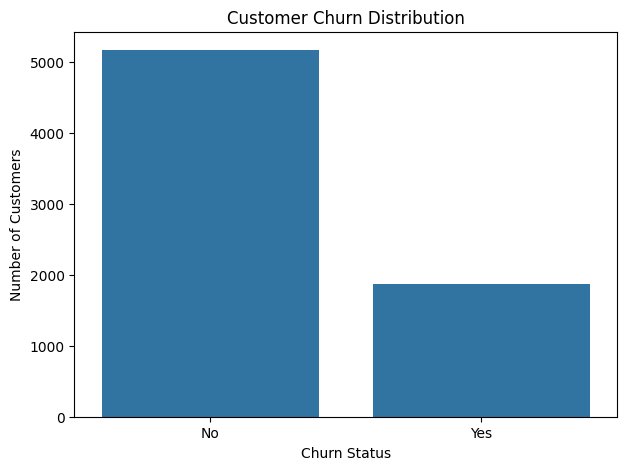

In [10]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.show()

Churn by Contract Type

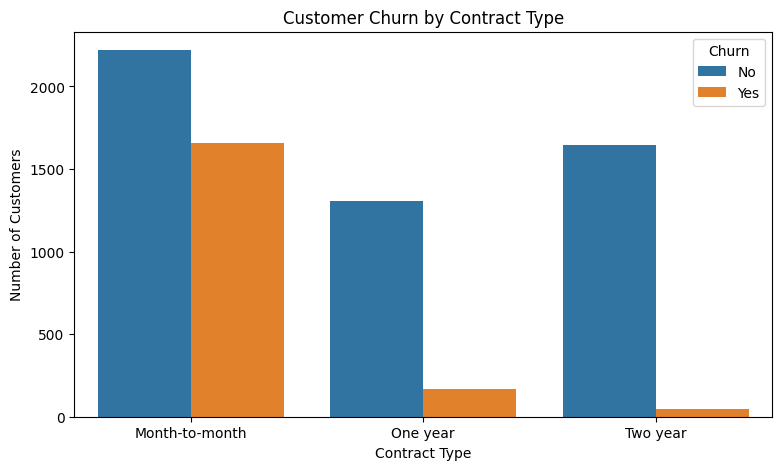

In [11]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x='Contract', hue='Churn')

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.show()

Churn by Internet Service

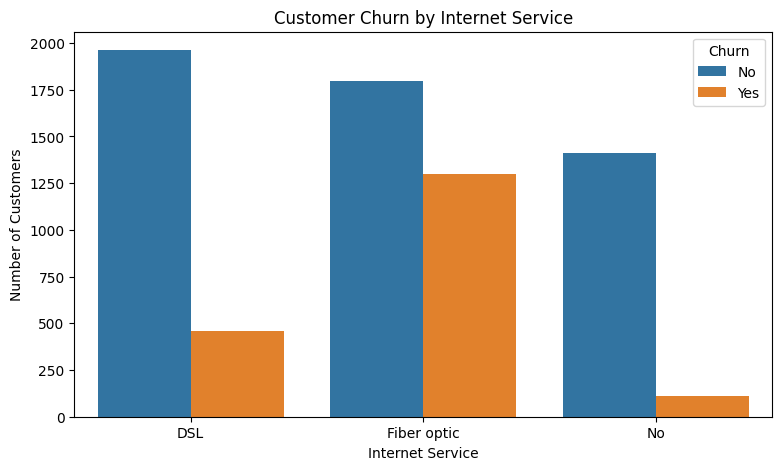

In [12]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x='InternetService', hue='Churn')

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')

plt.show()

Monthly Charges Distribution

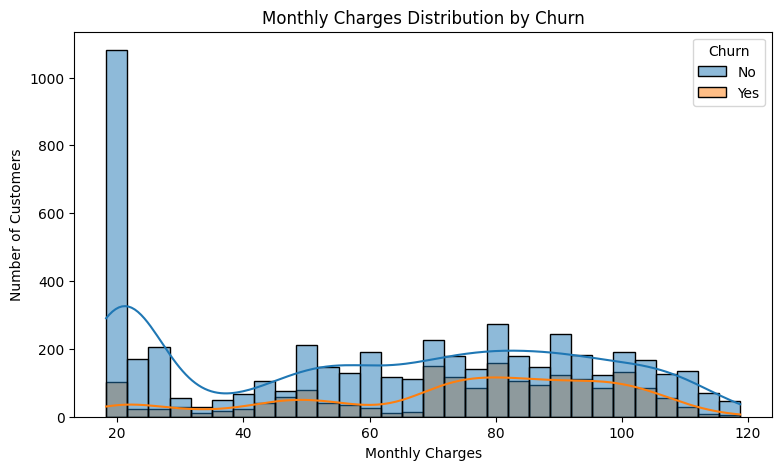

In [13]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='MonthlyCharges',
    hue='Churn',
    kde=True,
    bins=30
)

plt.title('Monthly Charges Distribution by Churn')
plt.xlabel('Monthly Charges')
plt.ylabel('Number of Customers')

plt.show()

In [14]:
plt.savefig('customer_churn_chart.png', dpi=300, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>